# 04 · Mapa extensivo de drift univariado

> Booster reconstruído com `scale_pos_weight=13.882494684620836`; corte 0,50 apenas para recall/precisão referenciais. A suíte anterior foi preservada.

**Pergunta:** para cada variável e direção, que PSI, KS de drift e distância Wasserstein são alcançados, e como mudam Brier, AUC ROC, PR-AUC trapezoidal e KS de discriminação? A grade contém 2.560 cenários de composição (10×8×32), mais trajetórias de ausência preexistente. **Todos são executados; não há limite arbitrário de aprovação ou parada.**

**Etapas replicáveis:** (1) congelar split, modelo e baseline; (2) definir perfis de reponderação a partir de X, sem usar Y; (3) fixar bins com referência original; (4) percorrer forças e registrar PSI/KS de drift, ESS e prevalência; (5) calcular as quatro métricas com pesos; (6) inspecionar curvas, deltas e extremos; (7) usar bootstrap pareado em cenários pré-fixados; (8) confirmar no tempo antes de criar uma política. Ao reponderar linhas inteiras, valores e Y permanecem reais; outras marginais correlacionadas podem mudar. O mecanismo representa mudança de composição dentro do suporte, com P(Y|X) estável.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve, roc_curve, auc as area_curva

P = DATA_DIR_PROJECT
DIR_DADOS = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
if DIR_DADOS is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
DIR_SAIDA = TABLES_DIR
MODELO = MODEL_DIR / 'model_class_retreinado.json'
MANIFESTO = MODEL_DIR / 'manifesto_modelo.json'
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
]
ALVO = 'SeriousDlqin2yrs'
LIMIAR = 0.50
SEMENTE = 33
for arquivo in [DIR_DADOS / 'cs-training.csv', MODELO, MANIFESTO]:
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
print('XGBoost:', xgb.__version__, '| Pasta de resultados:', DIR_SAIDA)

XGBoost: 3.0.0 | Pasta de resultados: .\results\tables


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Reconstituir a avaliação original

O arquivo `cs-test.csv` não traz rótulos. Portanto, qualquer afirmação de Brier, AUC, PR-AUC trapezoidal, KS do modelo, recall ou precisão vem exclusivamente do holdout de `cs-training.csv`. O mesmo `train_test_split(test_size=.15, random_state=33)` reproduz os índices de avaliação, sem `stratify`. O segundo split é mostrado para auditoria, mas não entra nas métricas. Conferimos feature order, árvore e linha de base com o manifesto antes do estresse. Árvores não têm um mínimo/máximo intrínseco de entrada; usamos os limites **empíricos do treino** e verificamos que nenhuma linha do holdout já os ultrapassa.

In [4]:
bruto = pd.read_csv(DIR_DADOS / 'cs-training.csv').drop(columns='Unnamed: 0')
assert list(bruto.drop(columns=ALVO).columns) == FEATURES
X_total, y_total = bruto[FEATURES], bruto[ALVO].astype(int)
X_train_val, X_hold, y_train_val, y_hold = train_test_split(
    X_total, y_total, test_size=.15, random_state=SEMENTE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=.1765, random_state=SEMENTE
)
assert (len(X_train), len(X_val), len(X_hold)) == (104996, 22504, 22500)
booster = xgb.Booster()
booster.load_model(str(MODELO))
assert booster.feature_names in (None, FEATURES)
booster.set_param({'device':'cpu'})
y = y_hold.to_numpy(dtype=np.int8)
p = np.asarray(booster.predict(xgb.DMatrix(
    X_hold[FEATURES], feature_names=FEATURES, enable_categorical=True
)), dtype=np.float64)
assert len(p) == len(y) and np.isfinite(p).all()
limites_treino = pd.DataFrame({'min_treino':X_train.min(), 'max_treino':X_train.max()})
fora_treino = pd.DataFrame({f: X_hold[f].notna() & ~X_hold[f].between(
    limites_treino.loc[f,'min_treino'],limites_treino.loc[f,'max_treino']) for f in FEATURES})
limites_treino['holdout_fora_min_max'] = fora_treino.mean()
assert not fora_treino.any().any(), 'O holdout contém valores fora dos limites empíricos de treino.'
manifesto = json.loads(MANIFESTO.read_text(encoding='utf-8'))
assert booster.num_boosted_rounds() == manifesto['num_boosted_rounds']
assert np.isclose(roc_auc_score(y,p), manifesto['baseline_holdout']['auc_roc'], atol=1e-8)
assert np.isclose(average_precision_score(y,p), manifesto['baseline_holdout']['ap'], atol=1e-8)
print(f'Treino: {len(X_train):,}; validação: {len(X_val):,}; holdout: {len(X_hold):,}; positivos: {y.sum():,}')
print('AUC:', round(roc_auc_score(y,p), 6), 'AP:', round(average_precision_score(y,p), 6))
display(limites_treino)

Treino: 104,996; validação: 22,504; holdout: 22,500; positivos: 1,500
AUC: 0.86684 AP: 0.396385


,min_treino,max_treino,holdout_fora_min_max
RevolvingUtilizationOfUnsecuredLines,0.0,50708.0,0.0
age,0.0,109.0,0.0
NumberOfTime30-59DaysPastDueNotWorse,0.0,98.0,0.0
DebtRatio,0.0,329664.0,0.0
MonthlyIncome,0.0,3008750.0,0.0
NumberOfOpenCreditLinesAndLoans,0.0,58.0,0.0
NumberOfTimes90DaysLate,0.0,98.0,0.0
NumberRealEstateLoansOrLines,0.0,54.0,0.0
NumberOfTime60-89DaysPastDueNotWorse,0.0,98.0,0.0
NumberOfDependents,0.0,13.0,0.0


## 2. Cálculo vetorizado e validação das métricas

O score e Y não mudam durante a reponderação, então ordenamos os scores uma vez e agrupamos empates. Para cada coluna de pesos, obtemos TPR e FPR cumulativos. **AUC ROC** é a área dessa curva; **KS do modelo** é o máximo de TPR−FPR; **PR-AUC trapezoidal** integra por trapézios a precisão em função do recall. **AP** é soma em degraus `precisão × incremento de recall`; fica como indicador auxiliar e não recebe o nome PR-AUC. **Brier** é média ponderada de $(y-p)^2$.

`recall` e `precision` são calculados em 0,50 apenas para leitura. ESS $(\sum w)^2/\sum w^2$ mostra concentração dos pesos, sem ser regra de exclusão. `ks_modelo` compara scores de eventos e não eventos; `ks_variavel` compara CDFs da entrada antes e depois do stress. Confirmamos as fórmulas vetorizadas contra `sklearn` inclusive com empates e pesos zero.

In [5]:
n_linhas = len(y)
ordem_score = np.argsort(-p, kind='stable')
p_ordenado = p[ordem_score]
y_ordenado = y[ordem_score]
inicio_grupos = np.r_[0, np.flatnonzero(np.diff(p_ordenado) != 0) + 1]
mascara_positiva = y == 1
mascara_negativa = ~mascara_positiva
mascara_decisao = p >= LIMIAR
erro_quadrado = (p-y)**2

def metricas_lote(W):
    # Métricas ponderadas exatas para colunas de cenários; scores e rótulos fixos.
    W = np.asarray(W, dtype=np.float64)
    if W.ndim == 1:
        W = W[:,None]
    assert W.shape[0] == n_linhas and np.isfinite(W).all() and (W >= 0).all()
    soma = W.sum(axis=0)
    assert (soma > 0).all()
    positivos = W[mascara_positiva].sum(axis=0)
    negativos = W[mascara_negativa].sum(axis=0)
    assert (positivos > 0).all() and (negativos > 0).all()

    W_ordenado = W[ordem_score]
    wp = np.add.reduceat(W_ordenado * y_ordenado[:,None], inicio_grupos, axis=0)
    wn = np.add.reduceat(W_ordenado * (1-y_ordenado)[:,None], inicio_grupos, axis=0)
    tp_acum = np.cumsum(wp, axis=0)
    fp_acum = np.cumsum(wn, axis=0)
    # Em ordem descendente: negativos abaixo do grupo atual + metade dos empatados.
    auc = np.sum(wp * (negativos[None,:]-fp_acum+0.5*wn), axis=0) / (positivos*negativos)
    denominador_grupo = tp_acum + fp_acum
    # Réplicas bootstrap podem ter peso zero nos grupos de score mais altos.
    # Precisão 0 nesses grupos não contribui para AP porque wp também é 0.
    precisao_grupo = np.divide(tp_acum, denominador_grupo,
                                out=np.zeros_like(tp_acum), where=denominador_grupo>0)
    ap = np.sum(precisao_grupo * wp, axis=0) / positivos
    recall_grupo = tp_acum / positivos[None,:]
    fpr_grupo = fp_acum / negativos[None,:]
    ks_modelo = np.maximum(0, np.max(recall_grupo - fpr_grupo, axis=0))
    denom_anterior = np.vstack([np.zeros((1,W.shape[1])), denominador_grupo[:-1]])
    precisao_anterior = np.vstack([np.ones((1,W.shape[1])), precisao_grupo[:-1]])
    precisao_anterior = np.where(denom_anterior > 0, precisao_anterior, 1.0)
    prauc_trap = np.sum((precisao_anterior + precisao_grupo) * 0.5 * wp / positivos[None,:], axis=0)

    tp = W[mascara_positiva & mascara_decisao].sum(axis=0)
    fp = W[mascara_negativa & mascara_decisao].sum(axis=0)
    prev = positivos / soma
    return pd.DataFrame({
        'auc': auc, 'prauc_trap': prauc_trap, 'ks_modelo': ks_modelo, 'ap': ap, 'ap_lift': ap/prev,
        'brier': erro_quadrado @ W / soma,
        'recall': tp/positivos,
        'precision': np.divide(tp, tp+fp, out=np.full_like(tp,np.nan), where=(tp+fp)>0),
        'fpr': fp/negativos, 'prevalencia': prev,
        'score_medio': p @ W / soma,
        'taxa_score_ge_050': (mascara_decisao.astype(float) @ W)/soma,
        'ess': soma**2 / np.square(W).sum(axis=0),
        'ess_frac': soma**2 / np.square(W).sum(axis=0) / n_linhas,
    })

rng_teste = np.random.default_rng(731)
W_teste = np.column_stack([
    np.ones(n_linhas),
    rng_teste.lognormal(0,.7,n_linhas),
    0.2 + rng_teste.random(n_linhas)**3,
    np.where(np.isin(np.arange(n_linhas),ordem_score[:100]),0.0,
             np.where(rng_teste.random(n_linhas)<.3,0.0,1.0)),
])
teste = metricas_lote(W_teste)
for j in range(W_teste.shape[1]):
    assert abs(teste.loc[j,'auc']-roc_auc_score(y,p,sample_weight=W_teste[:,j])) < 2e-12
    assert abs(teste.loc[j,'ap']-average_precision_score(y,p,sample_weight=W_teste[:,j])) < 2e-12
    _prec,_rec,_ = precision_recall_curve(y,p,sample_weight=W_teste[:,j])
    _fpr,_tpr,_ = roc_curve(y,p,sample_weight=W_teste[:,j])
    assert abs(teste.loc[j,'prauc_trap']-area_curva(_rec,_prec)) < 2e-12
    assert abs(teste.loc[j,'ks_modelo']-np.max(_tpr-_fpr)) < 2e-12
    assert abs(teste.loc[j,'brier']-brier_score_loss(y,p,sample_weight=W_teste[:,j])) < 2e-12
base = metricas_lote(np.ones(n_linhas)).iloc[0].to_dict()
display(pd.DataFrame([base],index=['Holdout original']).round(5))
print('AUC, AP, PR-AUC trapezoidal, KS do modelo e Brier conferidos com sklearn em quatro vetores de pesos.')

,auc,prauc_trap,ks_modelo,ap,ap_lift,brier,recall,precision,fpr,prevalencia,score_medio,taxa_score_ge_050,ess,ess_frac
Holdout original,0.86684,0.39599,0.58771,0.39639,5.94578,0.14404,0.794,0.21525,0.20676,0.06667,0.324,0.24591,22500.0,1.0


AUC, AP, PR-AUC trapezoidal, KS do modelo e Brier conferidos com sklearn em quatro vetores de pesos.


## 3. Desenho da grade univariada

Para cada variável, calculamos o percentil com empates pelo posto médio **apenas entre valores presentes**. Oito trajetórias, sempre com 32 intensidades positivas entre 0,025 e 3,2, favorecem:

1. valores crescentes (`alta_linear`) e decrescentes (`baixa_linear`);
2. caudas superiores e inferiores (`cauda_alta`, `cauda_baixa`), concentrando a inclinação nos quartis extremos; se o grande bloco de empates deixar uma cauda vazia, usamos o grupo de mínimo ou máximo observado;
3. diferenças crescentes ou decrescentes com ênfase cúbica nas extremidades (`alta_cubica`, `baixa_cubica`);
4. o centro e os extremos simultaneamente (`centro`, `extremos`).

Para um perfil `z_i`, os pesos dos valores presentes são `exp(intensidade × z_i)` divididos pela sua própria média. Os faltantes recebem peso 1; assim sua fração permanece igual à original nessas oito famílias. A função exponencial garante pesos positivos e uma trajetória contínua. Para variáveis que já têm faltantes, acrescentamos `ausencia_mais` e `ausencia_menos`, alterando somente a proporção de **linhas originalmente faltantes**; isso mede composição, não o erro de apagar valores em novos clientes. Intensidade alta pode produzir ESS pequeno: esses resultados são exibidos, e exigem interpretação cautelosa, sem reprovação automática.

Esta grade é sistemática, sem escolher casos individuais favoráveis. As trajetórias podem se aproximar em variáveis discretas com muitos empates; registramos a contagem de perfis distintos e não interpretamos o número de linhas da grade como número de fenômenos independentes.

In [6]:
INTENSIDADES = np.geomspace(.025, 3.2, 32)
assert len(INTENSIDADES) == 32 and INTENSIDADES.min() > 0

def perfis_variavel(serie):
    x = pd.Series(serie).reset_index(drop=True)
    presente = x.notna().to_numpy()
    r = np.full(len(x), np.nan)
    r[presente] = x[presente].rank(method='average',pct=True).to_numpy()
    u = 2*r[presente]-1
    perfis = {
        'alta_linear': u,
        'baixa_linear': -u,
        'cauda_alta': np.maximum(u-.5,0)*2,
        'cauda_baixa': np.maximum(-u-.5,0)*2,
        'alta_cubica': u**3,
        'baixa_cubica': -u**3,
        'centro': -np.abs(u),
        'extremos': np.abs(u),
    }
    valores = x[presente].to_numpy()
    if np.ptp(perfis['cauda_alta']) < 1e-12:
        perfis['cauda_alta'] = (valores == np.max(valores)).astype(float)
    if np.ptp(perfis['cauda_baixa']) < 1e-12:
        perfis['cauda_baixa'] = (valores == np.min(valores)).astype(float)
    for nome,z in perfis.items():
        if np.ptp(z) < 1e-12:
            raise AssertionError(f'Perfil sem alteração: {x.name}, {nome}')
    return presente, perfis

def pesos_perfil(presente, z, intensidades):
    intensidades = np.atleast_1d(intensidades)
    W = np.ones((n_linhas,len(intensidades)), dtype=np.float64)
    E = np.exp(np.asarray(z)[:,None] * intensidades[None,:])
    E /= E.mean(axis=0)[None,:]
    W[presente] = E
    return W

def pesos_ausencia(presente, direcao, intensidades):
    W = np.ones((n_linhas,len(intensidades)),dtype=np.float64)
    sinal = 1 if direcao=='ausencia_mais' else -1
    W[~presente] = np.exp(sinal*np.asarray(intensidades)[None,:])
    W /= W.mean(axis=0)[None,:]
    return W

perfis_cache = {f:perfis_variavel(X_hold[f]) for f in FEATURES}
fracao_ausente = X_hold[FEATURES].isna().mean()
variaveis_ausencia = fracao_ausente[(fracao_ausente > .005) & (fracao_ausente < .995)].index.tolist()
perfil_resumo = pd.DataFrame({
    'variavel': FEATURES,
    'valores_distintos': [X_hold[f].nunique(dropna=True) for f in FEATURES],
    'fracao_ausente': [fracao_ausente[f] for f in FEATURES],
})
display(perfil_resumo)
print('Variáveis com trajetórias extras de ausência:', variaveis_ausencia)

,variavel,valores_distintos,fracao_ausente
0,RevolvingUtilizationOfUnsecuredLines,19169,0.000000
1,age,83,0.000000
2,NumberOfTime30-59DaysPastDueNotWorse,12,0.000000
3,DebtRatio,19732,0.000000
4,MonthlyIncome,5540,0.196889
5,NumberOfOpenCreditLinesAndLoans,46,0.000000
6,NumberOfTimes90DaysLate,14,0.000000
7,NumberRealEstateLoansOrLines,19,0.000000
8,NumberOfTime60-89DaysPastDueNotWorse,11,0.000000
9,NumberOfDependents,10,0.027200


Variáveis com trajetórias extras de ausência: ['MonthlyIncome', 'NumberOfDependents']


## 4. Quantificar o drift que cada intensidade produziu

Uma intensidade exponencial não pode ser comparada diretamente entre variáveis. Para cada cenário, medimos **PSI marginal** em bins fixados no holdout original (quantis não repetidos mais categoria de faltante), **distância de Wasserstein 1** entre distribuições condicionais aos valores presentes e **KS ponderado**. W1 fica nas unidades da variável e também é dividido pela amplitude entre os percentis 5 e 95 para facilitar leitura. Calculamos ainda PSI dos scores, apesar de os scores individuais permanecerem fixos: a composição de pessoas com cada score muda.

PSI e KS não são métricas de acerto. W1 pode ser dominada por valores extremos reais, especialmente `DebtRatio` e utilização; a versão escalada usa faixa robusta, mas também deve ser lida com cuidado. Como não criamos linhas, o mínimo e máximo de cada coluna ficam preservados por construção e, conforme a checagem acima, não ultrapassam os limites empíricos de treino.

In [7]:
def preparar_bins(v):
    v = np.asarray(v,dtype=float)
    fin = np.isfinite(v)
    vf = v[fin]
    # Quantis mais densos nas caudas; side='left' separa a massa em zero
    # dos poucos valores positivos em variáveis de atrasos infladas em zero.
    cortes = np.unique(np.quantile(vf,np.r_[.01,.05,np.linspace(.1,.9,9),.95,.99]))
    grupos = np.full(len(v),len(cortes)+1,dtype=int)
    grupos[fin] = np.searchsorted(cortes,vf,side='left')
    B = np.eye(len(cortes)+2,dtype=float)[grupos]
    prop0 = B.mean(axis=0)
    return B, prop0

def psi_lote(B,prop0,W):
    q = (B.T @ W) / W.sum(axis=0)[None,:]
    eps = 1e-9
    return np.sum((q-prop0[:,None])*np.log((q+eps)/(prop0[:,None]+eps)),axis=0)

def preparar_w1(v):
    v = np.asarray(v,dtype=float)
    idx = np.flatnonzero(np.isfinite(v))
    idx = idx[np.argsort(v[idx],kind='stable')]
    xord = v[idx]
    escala = max(np.quantile(xord,.95)-np.quantile(xord,.05), 1e-12)
    return idx, np.diff(xord), np.arange(1,len(idx))/len(idx), escala

def w1_ks_lote(preparo,W):
    idx,dx,cdf0,escala = preparo
    S = W[idx]
    cdf = np.cumsum(S,axis=0)[:-1] / S.sum(axis=0)[None,:]
    diferenca = np.abs(cdf-cdf0[:,None])
    w1 = dx @ diferenca
    ks = np.max(diferenca,axis=0)
    return w1, w1/escala, ks

bin_cache = {f:preparar_bins(X_hold[f]) for f in FEATURES}
w1_cache = {f:preparar_w1(X_hold[f]) for f in FEATURES}
B_score, prop_score = preparar_bins(p)
for f in FEATURES:
    B,b = bin_cache[f]
    assert abs(psi_lote(B,b,np.ones((n_linhas,1)))[0]) < 1e-12
    assert abs(w1_ks_lote(w1_cache[f],np.ones((n_linhas,1)))[0][0]) < 1e-9
print('PSI e W1 iguais a zero para o holdout não alterado.')

PSI e W1 iguais a zero para o holdout não alterado.

## 5. Executar toda a grade

Cada coluna do lote é um cenário e todas as intensidades são processadas. Guardamos o valor da métrica e a diferença contra o holdout original. PSI mede mudança da marginal escolhida; KS da variável e Wasserstein são outras distâncias de drift, distintas do KS supervisionado do modelo. A relação intensidade→PSI não é linear nem comparável diretamente entre variáveis.

In [8]:
linhas = []
for f in FEATURES:
    presente, perfis = perfis_cache[f]
    B, prop = bin_cache[f]
    for trajetoria,z in perfis.items():
        W = pesos_perfil(presente,z,INTENSIDADES)
        m = metricas_lote(W)
        w1,w1_esc,ks = w1_ks_lote(w1_cache[f],W)
        m.insert(0,'variavel',f)
        m.insert(1,'trajetoria',trajetoria)
        m.insert(2,'intensidade',INTENSIDADES)
        m['familia'] = 'composicao_valores'
        m['psi_variavel'] = psi_lote(B,prop,W)
        m['w1_variavel'] = w1
        m['w1_escala_p05_p95'] = w1_esc
        m['ks_variavel'] = ks
        m['psi_score'] = psi_lote(B_score,prop_score,W)
        m['fracao_ausente_cenario'] = W[~presente].sum(axis=0)/W.sum(axis=0)
        linhas.append(m)
    if f in variaveis_ausencia:
        for trajetoria in ['ausencia_mais','ausencia_menos']:
            W = pesos_ausencia(presente,trajetoria,INTENSIDADES)
            m = metricas_lote(W)
            w1,w1_esc,ks = w1_ks_lote(w1_cache[f],W)
            m.insert(0,'variavel',f)
            m.insert(1,'trajetoria',trajetoria)
            m.insert(2,'intensidade',INTENSIDADES)
            m['familia'] = 'composicao_ausencia_existente'
            m['psi_variavel'] = psi_lote(B,prop,W)
            m['w1_variavel'] = w1
            m['w1_escala_p05_p95'] = w1_esc
            m['ks_variavel'] = ks
            m['psi_score'] = psi_lote(B_score,prop_score,W)
            m['fracao_ausente_cenario'] = W[~presente].sum(axis=0)/W.sum(axis=0)
            linhas.append(m)

resultados = pd.concat(linhas,ignore_index=True)
for campo in ['auc','prauc_trap','ks_modelo','brier','ap','ap_lift','recall','precision','fpr','prevalencia','score_medio','taxa_score_ge_050']:
    resultados['delta_'+campo] = resultados[campo]-base[campo]
assert len(resultados) >= 2560
assert resultados.groupby(['variavel','trajetoria']).size().eq(32).all()
assert np.isfinite(resultados[['auc','prauc_trap','ks_modelo','brier','ess','psi_variavel','w1_variavel']]).all().all()
print(f'Cenários de composição de valores: {10*8*32:,}')
print(f'Cenários extras de ausência: {len(resultados)-10*8*32:,}')
print(f'Total: {len(resultados):,}; cada métrica foi calculada em todos.')
display(resultados.groupby('trajetoria')[['psi_variavel','ess_frac','auc','prauc_trap','ks_modelo','brier']].agg(['min','median','max']).round(4))

Cenários de composição de valores: 2,560
Cenários extras de ausência: 128
Total: 2,688; cada métrica foi calculada em todos.


psi_variavel                 ess_frac                  auc  \
                        min  median     max      min  median  max     min   
trajetoria                                                                  
alta_cubica             0.0  0.0070  1.5369   0.2153  0.9929  1.0  0.8310   
alta_linear             0.0  0.0165  2.1965   0.1521  0.9829  1.0  0.8164   
ausencia_mais           0.0  0.0059  2.1137   0.1551  0.9933  1.0  0.8669   
ausencia_menos          0.0  0.0045  0.5984   0.8189  0.9961  1.0  0.8548   
baixa_cubica            0.0  0.0067  1.5322   0.2525  0.9941  1.0  0.8326   
baixa_linear            0.0  0.0151  2.1859   0.3115  0.9868  1.0  0.8299   
cauda_alta              0.0  0.0048  1.3057   0.1966  0.9947  1.0  0.8369   
cauda_baixa             0.0  0.0048  1.2306   0.2769  0.9948  1.0  0.8313   
centro                  0.0  0.0045  0.7636   0.5692  0.9958  1.0  0.8320   
extremos                0.0  0.0052  1.2835   0.2018  0.9947  1.0  0.8437   

                               prauc_trap                 ks_modelo          \
                median     max        min  median     max       min  median   
trajetoria                                                                    
alta_cubica     0.8671  0.8887     0.3335  0.3974  0.5898    0.5247  0.5878   
alta_linear     0.8668  0.8869     0.3156  0.3978  0.5874    0.4917  0.5877   
ausencia_mais   0.8680  0.9055     0.3898  0.3962  0.4622    0.5878  0.5895   
ausencia_menos  0.8661  0.8668     0.3800  0.3958  0.3964    0.5659  0.5866   
baixa_cubica    0.8663  0.8883     0.2582  0.3947  0.4420    0.5288  0.5867   
baixa_linear    0.8666  0.8903     0.2438  0.3950  0.4474    0.5270  0.5876   
cauda_alta      0.8673  0.8880     0.3517  0.3976  0.5866    0.5321  0.5886   
cauda_baixa     0.8669  0.8890     0.2534  0.3957  0.4367    0.5271  0.5877   
centro          0.8660  0.8706     0.2571  0.3925  0.3979    0.5283  0.5859   
extremos        0.8674  0.8872     0.3820  0.3990  0.5806    0.5326  0.5888   

                         brier                  
                   max     min  median     max  
trajetoria                                      
alta_cubica     0.6425  0.0796  0.1446  0.2790  
alta_linear     0.6364  0.0709  0.1451  0.3245  
ausencia_mais   0.6749  0.1087  0.1429  0.1440  
ausencia_menos  0.5877  0.1441  0.1448  0.1540  
baixa_cubica    0.6385  0.0731  0.1437  0.2056  
baixa_linear    0.6471  0.0542  0.1432  0.2107  
cauda_alta      0.6394  0.0867  0.1449  0.2878  
cauda_baixa     0.6397  0.0911  0.1435  0.1993  
centro          0.6009  0.1071  0.1432  0.1513  
extremos        0.6363  0.1294  0.1450  0.2797

## 6. Resumo descritivo da resposta

Para cada variável×trajetória, resumimos a **amplitude observada** do PSI, ESS e dos deltas das quatro métricas. `delta = cenário − baseline`; AUC, PR-AUC e KS menores significam perda de discriminação, enquanto Brier maior indica pior erro quadrático. Não calculamos uma “primeira falha” porque não existe custo de negócio ou tolerância validada que defina esse conceito. Valores extremos na grade não devem ser anunciados como tolerância de produção.

In [9]:
CAMPOS_CENTRAIS = ['brier','auc','prauc_trap','ks_modelo']
resumo = resultados.groupby(['variavel','trajetoria'],as_index=False).agg(
    n_cenarios=('intensidade','count'), psi_min=('psi_variavel','min'),
    psi_max=('psi_variavel','max'), ess_frac_min=('ess_frac','min'),
    brier_min=('brier','min'), brier_max=('brier','max'),
    auc_min=('auc','min'), auc_max=('auc','max'),
    prauc_trap_min=('prauc_trap','min'), prauc_trap_max=('prauc_trap','max'),
    ks_modelo_min=('ks_modelo','min'), ks_modelo_max=('ks_modelo','max'))
for campo in CAMPOS_CENTRAIS:
    extremos = resultados.groupby(['variavel','trajetoria'])[f'delta_{campo}'].agg(['min','max']).reset_index()
    resumo = resumo.merge(extremos.rename(columns={'min':f'delta_{campo}_min','max':f'delta_{campo}_max'}),
                          on=['variavel','trajetoria'])
display(resumo.round(5))

,variavel,trajetoria,n_cenarios,psi_min,psi_max,ess_frac_min,brier_min,brier_max,auc_min,auc_max,prauc_trap_min,prauc_trap_max,ks_modelo_min,ks_modelo_max,delta_brier_min,delta_brier_max,delta_auc_min,delta_auc_max,delta_prauc_trap_min,delta_prauc_trap_max,delta_ks_modelo_min,delta_ks_modelo_max
0,DebtRatio,alta_cubica,32,0.00009,1.53610,0.25207,0.13192,0.14404,0.85632,0.86676,0.39606,0.40480,0.57235,0.58757,-0.01211,-0.00000,-0.01052,-0.00008,0.00007,0.00881,-0.01536,-0.00015
1,DebtRatio,alta_linear,32,0.00021,2.18618,0.31146,0.13396,0.14615,0.86438,0.86937,0.39613,0.42509,0.58226,0.59548,-0.01008,0.00211,-0.00246,0.00253,0.00014,0.02910,-0.00545,0.00777
2,DebtRatio,baixa_cubica,32,0.00009,1.52844,0.25806,0.13546,0.14404,0.86692,0.88828,0.39444,0.40068,0.58786,0.63855,-0.00858,-0.00000,0.00008,0.02144,-0.00155,0.00469,0.00015,0.05083
3,DebtRatio,baixa_linear,32,0.00021,2.18595,0.31189,0.12656,0.14391,0.86698,0.89031,0.39418,0.40360,0.58803,0.64712,-0.01748,-0.00013,0.00014,0.02347,-0.00181,0.00760,0.00032,0.05941
4,DebtRatio,cauda_alta,32,0.00004,1.23223,0.27659,0.12600,0.14393,0.86365,0.86888,0.39610,0.40871,0.58762,0.59298,-0.01804,-0.00010,-0.00319,0.00204,0.00011,0.01272,-0.00009,0.00527
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,age,baixa_linear,32,0.00021,2.18481,0.31152,0.14488,0.21066,0.84512,0.86662,0.39655,0.43022,0.53084,0.58714,0.00084,0.06662,-0.02172,-0.00022,0.00056,0.03423,-0.05688,-0.00057
80,age,cauda_alta,32,0.00004,1.23290,0.27662,0.08672,0.14376,0.86696,0.88213,0.35192,0.39585,0.58800,0.63882,-0.05731,-0.00028,0.00012,0.01529,-0.04407,-0.00014,0.00028,0.05110
81,age,cauda_baixa,32,0.00004,1.22766,0.27691,0.14429,0.19703,0.85044,0.86682,0.39623,0.41785,0.53983,0.58765,0.00025,0.05299,-0.01640,-0.00002,0.00024,0.02186,-0.04788,-0.00006
82,age,centro,32,0.00005,0.70762,0.57603,0.14409,0.15120,0.85296,0.86673,0.37334,0.39584,0.56056,0.58748,0.00005,0.00716,-0.01388,-0.00011,-0.02265,-0.00015,-0.02715,-0.00023


## 7. Visualizar distâncias e métricas

O primeiro mapa mostra **o maior PSI efetivamente alcançado** por trajetória. O painel de dispersão compara PSI com o delta das quatro métricas. As cores representam a variável e os pontos são cenários distintos. Linha horizontal zero = baseline, sem ser limite de aceitação. O último gráfico usa ESS para mostrar onde estimativas ficam concentradas. Sempre leia a direção e o mecanismo, pois mesmo PSI pode acompanhar impactos opostos.

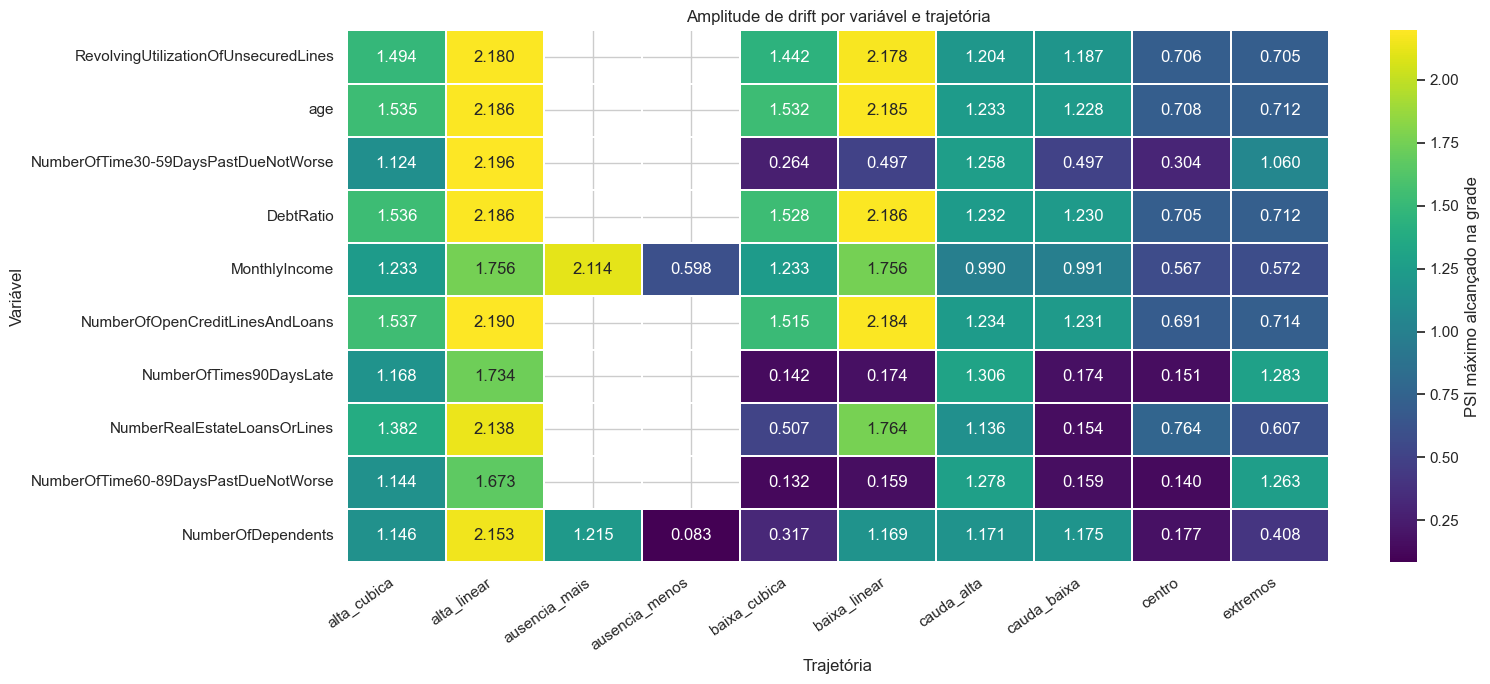

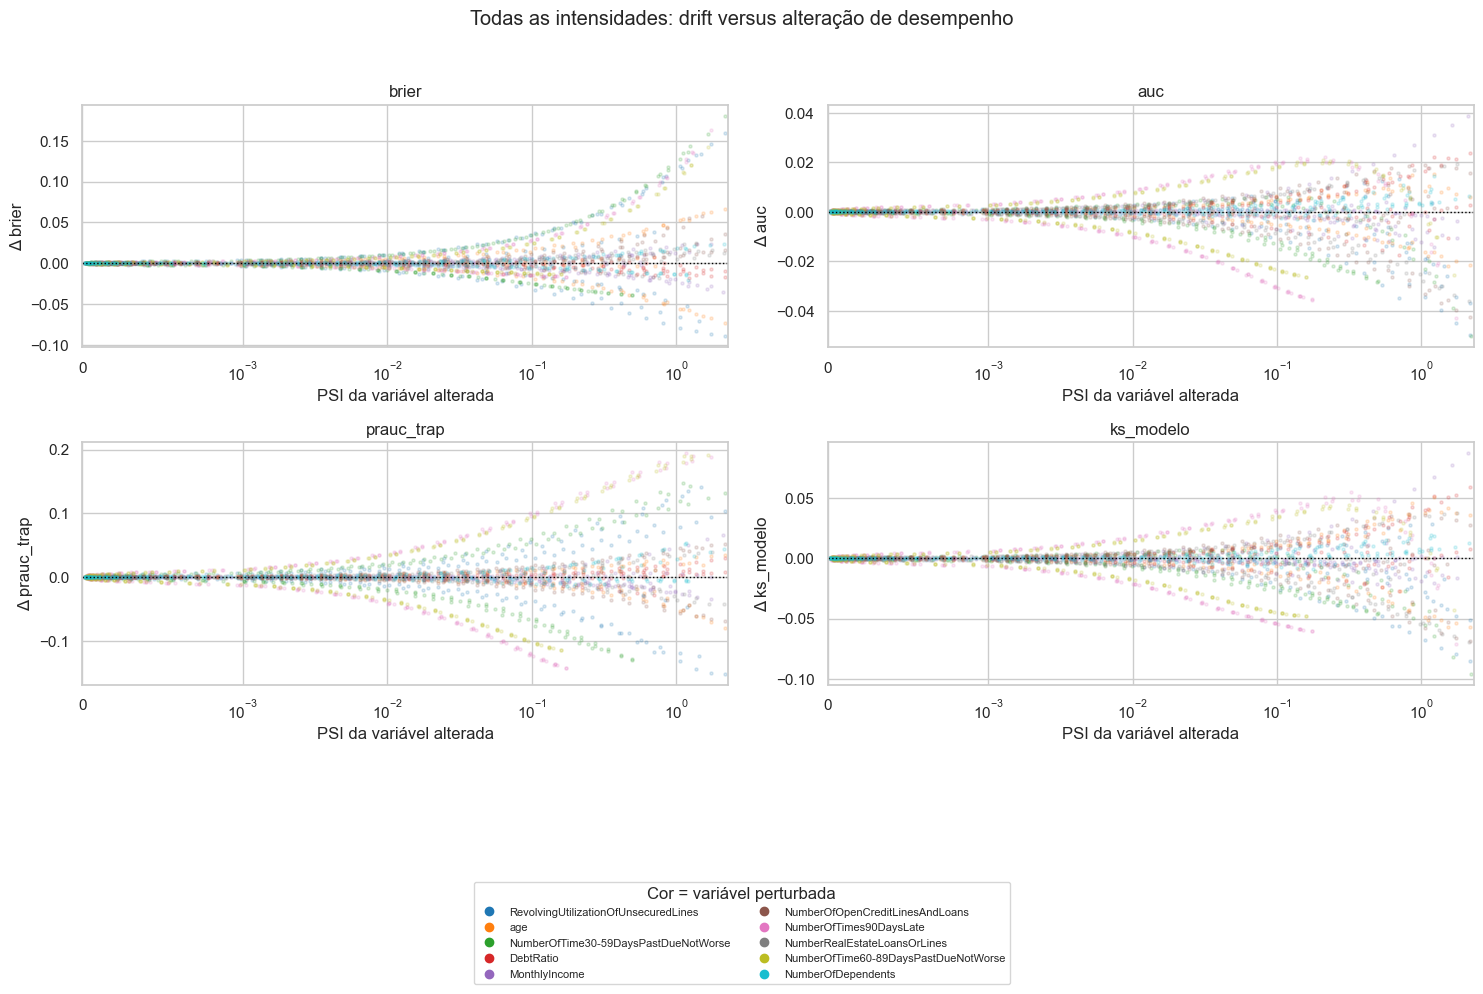

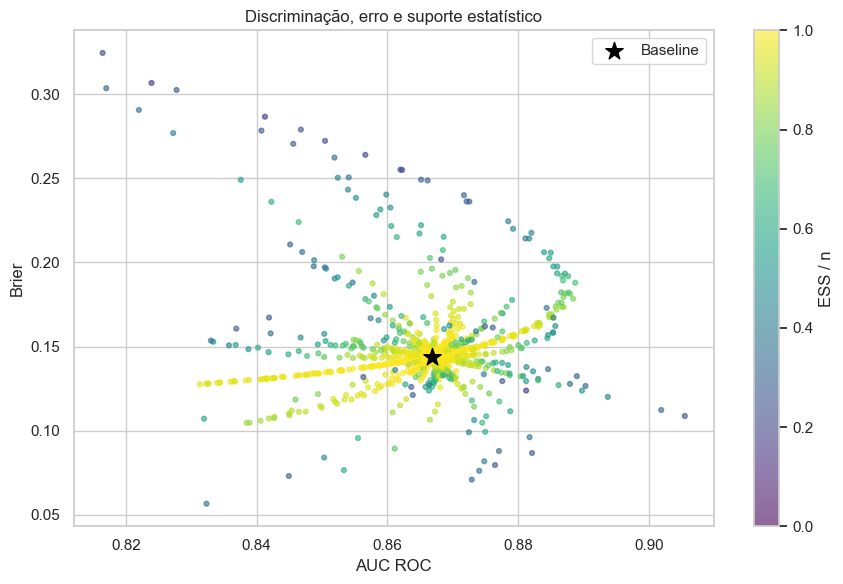

In [10]:
tab = resumo.pivot(index='variavel',columns='trajetoria',values='psi_max').reindex(FEATURES)
fig,ax = plt.subplots(figsize=(16,7))
sns.heatmap(tab,cmap='viridis',annot=True,fmt='.3f',linewidths=.3,
            cbar_kws={'label':'PSI máximo alcançado na grade'},ax=ax)
ax.set(title='Amplitude de drift por variável e trajetória',xlabel='Trajetória',ylabel='Variável')
plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.show()

fig,axs = plt.subplots(2,2,figsize=(15,10))
pal = dict(zip(FEATURES,sns.color_palette('tab10',len(FEATURES))))
for ax,campo in zip(axs.ravel(),CAMPOS_CENTRAIS):
    for f,g in resultados.groupby('variavel',sort=False):
        ax.scatter(g.psi_variavel,g[f'delta_{campo}'],color=pal[f],s=5,alpha=.16,rasterized=True)
    ax.axhline(0,color='black',ls=':',lw=1)
    ax.set(xlabel='PSI da variável alterada',ylabel=f'Δ {campo}',title=campo)
    ax.set_xscale('symlog',linthresh=.001); ax.set_xlim(left=0)
fig.suptitle('Todas as intensidades: drift versus alteração de desempenho')
from matplotlib.lines import Line2D
legenda_variaveis = [Line2D([0],[0],marker='o',linestyle='',color=pal[f],
                             markersize=6,label=f) for f in FEATURES]
fig.legend(handles=legenda_variaveis,loc='lower center',bbox_to_anchor=(.5,0),
           ncol=2,fontsize=8,title='Cor = variável perturbada')
fig.tight_layout(rect=(0,.23,1,.96)); plt.show()

fig,ax=plt.subplots(figsize=(9,6))
amostra = resultados.sample(min(1700,len(resultados)),random_state=33)
sc=ax.scatter(amostra['auc'],amostra['brier'],c=amostra['ess_frac'],cmap='viridis',
              s=12,alpha=.6,vmin=0,vmax=1,rasterized=True)
ax.scatter(base['auc'],base['brier'],marker='*',s=170,color='black',label='Baseline')
ax.set(xlabel='AUC ROC',ylabel='Brier',title='Discriminação, erro e suporte estatístico')
ax.legend();fig.colorbar(sc,ax=ax,label='ESS / n');plt.tight_layout();plt.show()

## 8. Bootstrap pareado em cenários pré-fixados

Escolhemos as cinco primeiras variáveis na ordem do modelo, trajetória `alta_linear` e a intensidade da grade mais próxima de 1, **sem selecionar pelo desempenho observado**. Em 150 réplicas, a mesma amostra de linhas define baseline e cenário; o intervalo percentil 95% é calculado sobre a diferença. Isto mostra incerteza de avaliação, condicional ao modelo/holdout/mecanismo. Os intervalos não são simultâneos para todos os milhares de cenários nem permitem declarar segurança em produção.

,variavel,trajetoria,intensidade,psi_variavel,metrica,delta_observado,ic95_inferior,ic95_superior
0,RevolvingUtilizationOfUnsecuredLines,alta_linear,1.06986,0.35185,brier,0.06904,0.06711,0.07062
1,RevolvingUtilizationOfUnsecuredLines,alta_linear,1.06986,0.35185,auc,-0.01681,-0.02322,-0.01103
2,RevolvingUtilizationOfUnsecuredLines,alta_linear,1.06986,0.35185,prauc_trap,0.05041,0.04357,0.05806
3,RevolvingUtilizationOfUnsecuredLines,alta_linear,1.06986,0.35185,ks_modelo,-0.04308,-0.06492,-0.02071
4,age,alta_linear,1.06986,0.35212,brier,-0.03431,-0.03569,-0.03306
5,age,alta_linear,1.06986,0.35212,auc,0.00708,0.00008,0.01424
6,age,alta_linear,1.06986,0.35212,prauc_trap,-0.02759,-0.04260,-0.01363
7,age,alta_linear,1.06986,0.35212,ks_modelo,0.02418,0.00846,0.03966
8,NumberOfTime30-59DaysPastDueNotWorse,alta_linear,1.06986,0.21678,brier,0.05224,0.05054,0.05427
9,NumberOfTime30-59DaysPastDueNotWorse,alta_linear,1.06986,0.21678,auc,-0.00003,-0.00458,0.00480


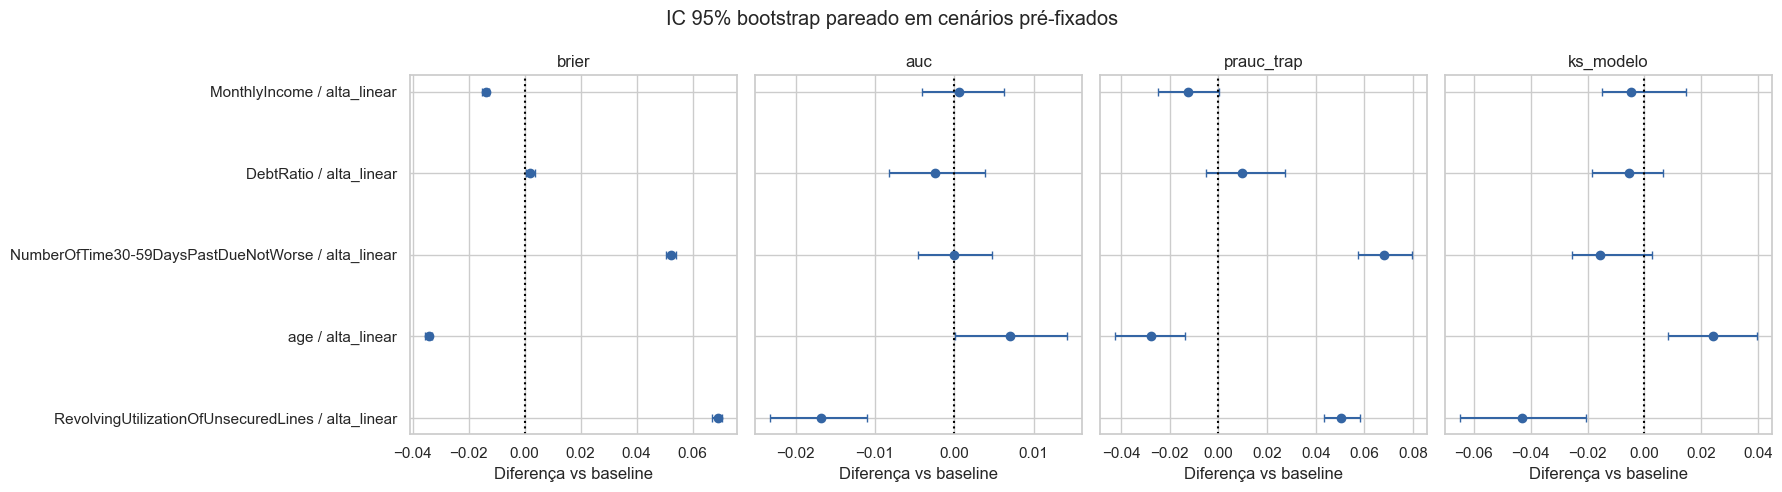

In [11]:
s = float(INTENSIDADES[np.argmin(np.abs(INTENSIDADES-1.0))])
selecionados = [(f,'alta_linear',s) for f in FEATURES[:5]]
BOOTSTRAPS = 150
rng_boot = np.random.default_rng(3304)
linhas_ic = []
for variavel,trajetoria,intensidade in selecionados:
    presente, perfis = perfis_cache[variavel]
    w = pesos_perfil(presente,perfis[trajetoria],[intensidade])[:,0]
    C = rng_boot.multinomial(n_linhas,np.full(n_linhas,1/n_linhas),size=BOOTSTRAPS).T
    mb = metricas_lote(C)
    ms = metricas_lote(C*w[:,None])
    obs = resultados[(resultados.variavel==variavel)&
                     (resultados.trajetoria==trajetoria)&
                     (np.isclose(resultados.intensidade,intensidade))].iloc[0]
    for campo in CAMPOS_CENTRAIS:
        dif = (ms[campo]-mb[campo]).to_numpy()
        li,ls = np.quantile(dif,[.025,.975])
        linhas_ic.append({'variavel':variavel,'trajetoria':trajetoria,
                          'intensidade':intensidade,'psi_variavel':obs.psi_variavel,
                          'metrica':campo,'delta_observado':obs[campo]-base[campo],
                          'ic95_inferior':li,'ic95_superior':ls})
incerteza = pd.DataFrame(linhas_ic)
assert np.isfinite(incerteza[['delta_observado','ic95_inferior','ic95_superior']]).all().all()
display(incerteza.round(5))
fig,axs=plt.subplots(1,4,figsize=(18,5),sharey=True)
for ax,(campo,g) in zip(axs,incerteza.groupby('metrica',sort=False)):
    g=g.reset_index(drop=True); yy=np.arange(len(g))
    ax.errorbar(g.delta_observado,yy,
                xerr=[g.delta_observado-g.ic95_inferior,g.ic95_superior-g.delta_observado],
                fmt='o',capsize=3,color='#3465a4')
    ax.axvline(0,color='black',ls=':')
    ax.set(yticks=yy,yticklabels=[v+' / '+t for v,t in zip(g.variavel,g.trajetoria)],
           xlabel='Diferença vs baseline',title=campo)
fig.suptitle('IC 95% bootstrap pareado em cenários pré-fixados')
plt.tight_layout();plt.show()

## 9. Arquivos e aplicação em outro contexto

O CSV detalhado tem **uma linha por cenário**, com trajetória, intensidade, PSI/KS de drift, ESS e todas as métricas/deltas. O resumo contém mínimo e máximo por variável×trajetória. Para outro dataset: troque o manifesto, as colunas e o split; escolha perfis coerentes com o domínio; defina bins na população de referência e congele-os; valide as métricas vetorizadas; interprete a grade como conjunto de hipóteses, nunca como limite universal. Somente séries temporais rotuladas permitem confirmar degradação real.

In [12]:
ARQUIVO_RESULTADOS = DIR_SAIDA/'resultados_univariado_extensivo.csv'
ARQUIVO_RESUMO = DIR_SAIDA/'resumo_univariado_extensivo.csv'
resultados.to_csv(ARQUIVO_RESULTADOS,index=False,encoding='utf-8-sig')
resumo.to_csv(ARQUIVO_RESUMO,index=False,encoding='utf-8-sig')
assert len(pd.read_csv(ARQUIVO_RESULTADOS))==len(resultados)
assert len(pd.read_csv(ARQUIVO_RESUMO))==len(resumo)
display(resumo.sort_values('delta_ks_modelo_min').head(10)[
 ['variavel','trajetoria','psi_max','ess_frac_min','delta_auc_min','delta_prauc_trap_min',
  'delta_ks_modelo_min','delta_brier_max']].round(5))
display(Markdown(f'**Execução concluída:** {len(resultados):,} cenários, '
                 f'{resultados.variavel.nunique()} variáveis, {len(resumo)} trajetórias. '
                 f'Arquivos: `{ARQUIVO_RESULTADOS.name}` e `{ARQUIVO_RESUMO.name}`.'))

,variavel,trajetoria,psi_max,ess_frac_min,delta_auc_min,delta_prauc_trap_min,delta_ks_modelo_min,delta_brier_max
37,NumberOfTime30-59DaysPastDueNotWorse,alta_linear,2.19647,0.21787,-0.05039,0.00177,-0.09599,0.18049
69,RevolvingUtilizationOfUnsecuredLines,alta_linear,2.18002,0.31448,-0.04983,0.00148,-0.08537,0.15953
53,NumberOfTimes90DaysLate,alta_linear,1.73421,0.15363,-0.04292,0.00225,-0.07117,0.16264
61,NumberRealEstateLoansOrLines,alta_linear,2.13775,0.30799,-0.03622,-0.04319,-0.06975,0.01289
29,NumberOfOpenCreditLinesAndLoans,alta_linear,2.19040,0.31101,-0.04265,-0.06884,-0.06872,0.01557
60,NumberRealEstateLoansOrLines,alta_cubica,1.38238,0.24008,-0.03019,-0.03245,-0.06302,0.02407
55,NumberOfTimes90DaysLate,baixa_linear,0.17377,0.94780,-0.03561,-0.14316,-0.06070,-0.00040
57,NumberOfTimes90DaysLate,cauda_baixa,0.17379,0.94778,-0.03553,-0.14263,-0.06060,-0.00040
58,NumberOfTimes90DaysLate,centro,0.15103,0.94974,-0.03458,-0.13888,-0.05937,-0.00036
54,NumberOfTimes90DaysLate,baixa_cubica,0.14185,0.95087,-0.03421,-0.13779,-0.05887,-0.00034


**Execução concluída:** 2,688 cenários, 10 variáveis, 84 trajetórias. Arquivos: `resultados_univariado_extensivo.csv` e `resumo_univariado_extensivo.csv`.